In [12]:
#importing library
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import data_utils as du

In [13]:
#Importing the dataset
reg_path= "../../data/Regression_datasets/it_infra.csv"
reg_data= pd.read_csv(reg_path)
print(reg_data.head())

   requests     memory  users   cpu_usage
0       175  14.377985     80   74.239716
1       200   3.006782     92   48.563785
2       186  27.010520    115  100.966288
3       175  28.885040    106  114.889753
4       190  30.501809     93  110.342123


In [14]:
#data exploration
du.data_exploration(reg_data)

DATA EXPLORATION
Shape of dataset: 10000 rows, 4 columns

Columns: ['requests', 'memory', 'users', 'cpu_usage']

Data Types:
 requests       int64
memory       float64
users          int64
cpu_usage    float64
dtype: object

Missing Values:
 requests     0
memory       0
users        0
cpu_usage    0
dtype: int64

Statistical Summary:
            requests        memory         users     cpu_usage
count  10000.000000  10000.000000  10000.000000  10000.000000
mean     199.818400     16.960661    100.004100     83.834598
std       14.024753      8.663870     10.007422     18.362847
min      150.000000      2.000603     61.000000     35.310821
25%      190.000000      9.480979     93.000000     68.867690
50%      200.000000     16.954169    100.000000     83.739754
75%      209.000000     24.505668    107.000000     98.927300
max      258.000000     31.999889    138.000000    128.470950


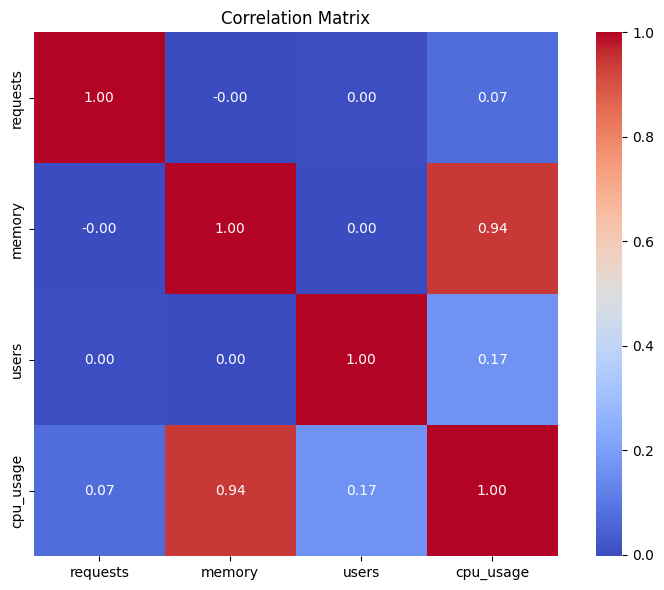

In [15]:
#data visualization
corr = du.get_correlation_matrix(reg_data)
du.plot_correlation_matrix(corr)

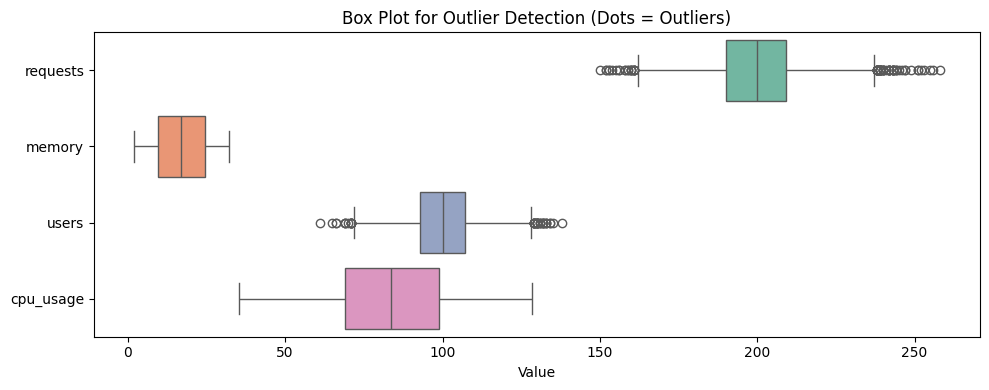

In [16]:
#check for outliers
cols = reg_data.columns
du.plot_boxplots(reg_data, cols)

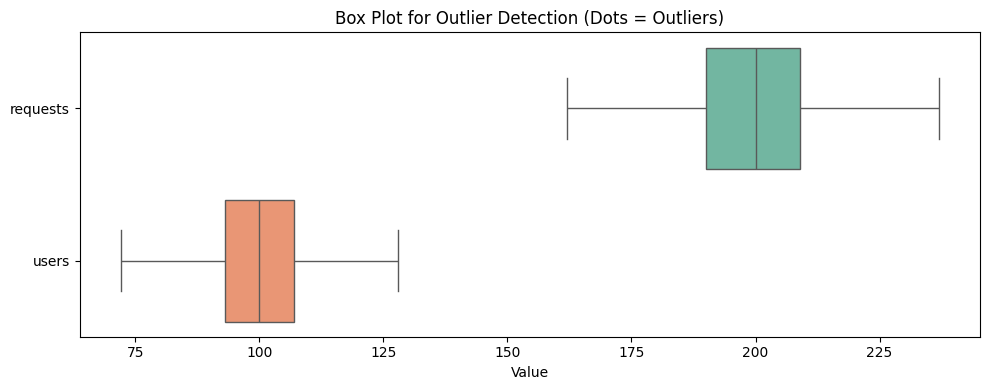

In [17]:
outlier_cols = ['requests','users']
df_clean = du.remove_outliers_iqr(reg_data, outlier_cols)
du.plot_boxplots(df_clean, outlier_cols)

In [18]:
#linear regression 
X = df_clean.drop('cpu_usage', axis=1)
y = df_clean['cpu_usage']

In [19]:
model, mse, r2, y_test, y_pred =    du.linear_regression_model(X, y)

Mean Squared Error: 25.3969
R-squared: 0.9255


/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


In [20]:
du.cross_validation(model, X, y, cv=5)

5-Fold Cross-Validation (r2): [0.92120881 0.92740427 0.92363242 0.92571025 0.92181923]
Average CV score: 0.9240 (± 0.0023)


/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: i

array([0.92120881, 0.92740427, 0.92363242, 0.92571025, 0.92181923])

92% prediction accuracy can able to attain using this data


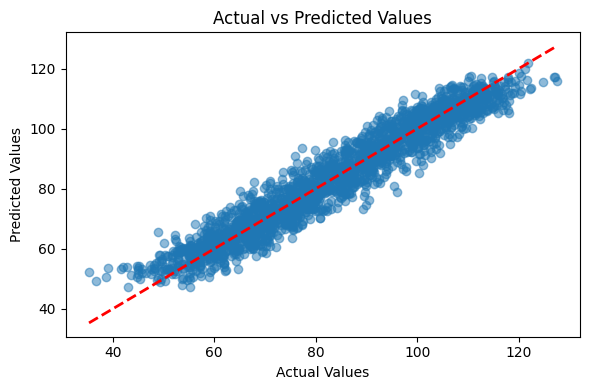

In [21]:
du.plot_actual_vs_predicted(y_test, y_pred)